In [42]:
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import numpy as np

In [17]:
ROOT = Path.cwd().parents[0]
DF_INTERIM = ROOT / 'data' / 'interim'
DF_PROCESSED = ROOT / 'data' / 'processed'

In [20]:
tb1 = pd.read_csv(DF_PROCESSED / 'cv_last_observations.csv')
tb1.head()

,oid,days_since_last_observation
0,ZTF17aaabzwf,3
1,ZTF17aaaasgw,3
2,ZTF17aaafbql,3
3,ZTF17aaaawjm,3
4,ZTF17aaaerje,3


In [46]:
tb1.days_since_last_observation.max()

np.int64(513)

(array([ 77.,  80.,  44.,  20.,  43., 129.,  50.,  42.,  20.,  13.]),
 array([  3.,  54., 105., 156., 207., 258., 309., 360., 411., 462., 513.]),
 <BarContainer object of 10 artists>)

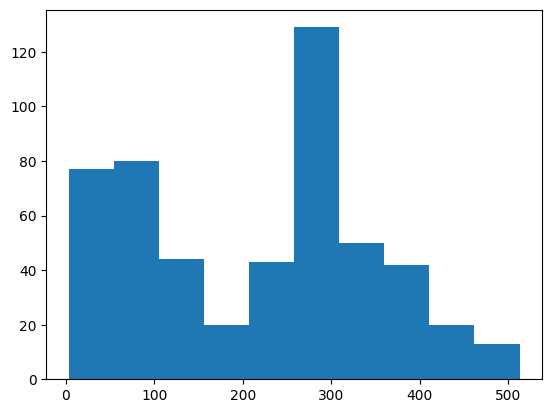

In [47]:
plt.hist(tb1.days_since_last_observation)

In [80]:
cv_1 = pd.read_csv(DF_INTERIM / 'cv_mag_1_var.csv')
tb2 = cv_1.copy()
tb2 = cv_1[['oid', 'amplitude_diff', 'magpsf']]
tb2

,oid,amplitude_diff,magpsf
0,ZTF17aaaaabx,0.375221,20.136703
1,ZTF17aaaaafj,1.077303,19.191401
2,ZTF17aaaaafv,0.174719,20.830799
3,ZTF17aaaaait,0.396739,20.425100
4,ZTF17aaaaanm,1.795005,19.306021
...,...,...,...
327,ZTF17aaafhrl,1.889057,17.782915
328,ZTF17aaafhte,0.453110,18.123032
329,ZTF17aaafieu,1.579425,17.415955
330,ZTF17aaafife,0.873882,17.772800


(array([ 1.,  2.,  5., 12., 20., 34., 62., 83., 81., 32.]),
 array([12.5698185 , 13.39961662, 14.22941475, 15.05921288, 15.889011  ,
        16.71880913, 17.54860725, 18.37840538, 19.20820351, 20.03800163,
        20.86779976]),
 <BarContainer object of 10 artists>)

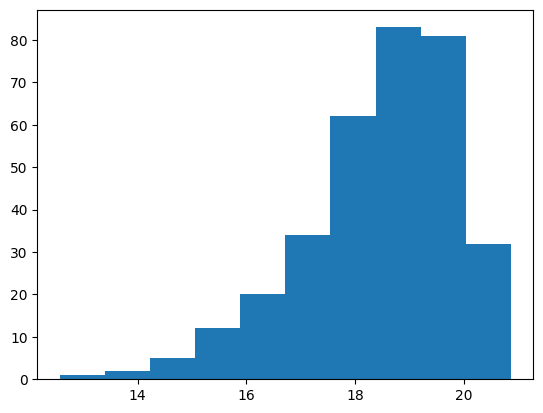

In [88]:
plt.hist(tb2.magpsf)

In [119]:
tb3 = pd.merge(left=cv_1, right=tb1, on='oid', how='left')
tb3

,oid,amplitude_diff,magpsf,sigmapsf,observed_at,days_since_last_observation
0,ZTF17aaaaabx,0.375221,20.136703,0.186771,2024-10-24 08:32:42.996+00,281
1,ZTF17aaaaafj,1.077303,19.191401,0.096761,2025-12-22 04:50:42+00,295
2,ZTF17aaaaafv,0.174719,20.830799,0.273123,2019-10-09 10:38:18.001+00,257
3,ZTF17aaaaait,0.396739,20.425100,0.201617,2025-08-30 06:58:26+00,415
4,ZTF17aaaaanm,1.795005,19.306021,0.118422,2025-12-11 03:40:31.996+00,312
...,...,...,...,...,...,...
327,ZTF17aaafhrl,1.889057,17.782915,0.104703,2026-02-01 03:17:43.999+00,260
328,ZTF17aaafhte,0.453110,18.123032,0.118244,2022-11-19 07:41:05.997+00,113
329,ZTF17aaafieu,1.579425,17.415955,0.101694,2025-10-03 09:52:18.998+00,281
330,ZTF17aaafife,0.873882,17.772800,0.157642,2026-01-15 03:54:09.996+00,277


In [120]:
tb3['recent_score'] = 40 * 2**(-tb3['days_since_last_observation'] / 90)
tb3['variation_score'] = 10 * tb3['amplitude_diff']
tb3['brightness_score'] = 30 * 18/tb3['magpsf']
tb3['total_score'] = tb3.recent_score + tb3.variation_score + tb3.brightness_score
tb3.head()
# tb3[['oid'], ['days_since_last_observation'], ['recent_score'], ['amplitude_diff'], ['variation_score'], ['magpsf'], ['brightness_score']]

,oid,amplitude_diff,magpsf,sigmapsf,observed_at,days_since_last_observation,recent_score,variation_score,brightness_score,total_score
0,ZTF17aaaaabx,0.375221,20.136703,0.186771,2024-10-24 08:32:42.996+00,281,4.593857,3.752213,26.816703,35.162772
1,ZTF17aaaaafj,1.077303,19.191401,0.096761,2025-12-22 04:50:42+00,295,4.124303,10.773031,28.137603,43.034937
2,ZTF17aaaaafv,0.174719,20.830799,0.273123,2019-10-09 10:38:18.001+00,257,5.526525,1.747192,25.923153,33.196870
3,ZTF17aaaaait,0.396739,20.425100,0.201617,2025-08-30 06:58:26+00,415,1.636731,3.967388,26.438059,32.042178
4,ZTF17aaaaanm,1.795005,19.306021,0.118422,2025-12-11 03:40:31.996+00,312,3.618173,17.950050,27.970549,49.538772


In [122]:
tb3 = tb3[['oid', 'recent_score', 'variation_score', 'brightness_score', 'total_score']]
tb3 = tb3.sort_values(by='total_score', ascending=False).iloc[0:10]
tb3

,oid,recent_score,variation_score,brightness_score,total_score
146,ZTF17aaadasj,37.034988,56.029002,30.294192,123.358182
145,ZTF17aaadars,39.086399,27.871699,28.131779,95.089877
317,ZTF17aaafglk,39.086399,23.400183,31.974413,94.460994
110,ZTF17aaabfay,39.086399,19.207314,32.635550,90.929263
77,ZTF17aaaazob,16.497212,46.205025,26.806191,89.508428
154,ZTF17aaadosk,38.786526,18.578224,31.276782,88.641532
266,ZTF17aaaenve,5.236471,40.123295,42.960048,88.319813
85,ZTF17aaabarf,36.750854,17.035804,33.245777,87.032435
277,ZTF17aaaeoum,18.234450,28.477065,40.020785,86.732300
118,ZTF17aaablms,2.519328,46.658594,36.965267,86.143190


In [124]:
tb3.to_csv(DF_PROCESSED / 'cv_scores.csv', index=False)

In [ ]:
tb2['is_10'] = tb2.oid.isin(tb3.oid).map({True: 'TOP 10', False: 'OTHER'})
tb2

,oid,amplitude_diff,magpsf,is_10
0,ZTF17aaaaabx,0.375221,20.136703,OTHER
1,ZTF17aaaaafj,1.077303,19.191401,OTHER
2,ZTF17aaaaafv,0.174719,20.830799,OTHER
3,ZTF17aaaaait,0.396739,20.425100,OTHER
4,ZTF17aaaaanm,1.795005,19.306021,OTHER
...,...,...,...,...
327,ZTF17aaafhrl,1.889057,17.782915,OTHER
328,ZTF17aaafhte,0.453110,18.123032,OTHER
329,ZTF17aaafieu,1.579425,17.415955,OTHER
330,ZTF17aaafife,0.873882,17.772800,OTHER


In [136]:
tb2.to_csv(DF_PROCESSED / 'cv_mag_1_var.csv', index=False)

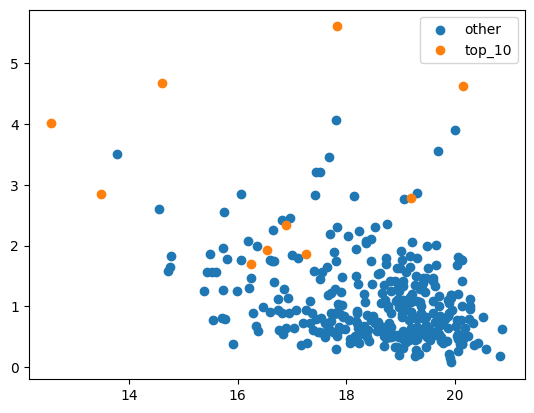

In [135]:
plt.scatter(tb2[tb2.is_10=='OTHER'].magpsf, tb2[tb2.is_10=='OTHER'].amplitude_diff, label='other')
plt.scatter(tb2[tb2.is_10=='TOP 10'].magpsf, tb2[tb2.is_10=='TOP 10'].amplitude_diff, label='top_10')
plt.legend()